### **CSC784-FinalProject: ZtScore Telemetry Generator**

### 1. Setup - Upload ztscore-telemetry.zip and run this cell (Unzips and grabs files for use)

In [ ]:
import os, sys, zipfile
try:
    from google.colab import files
    if not os.path.exists("ztscore-telemetry"):
        uploaded = files.upload()                    # pick ztscore-telemetry.zip
        zipfile.ZipFile(next(iter(uploaded))).extractall(".")
except ImportError:
    pass                                             # running outside Colab

sys.path.insert(0, "ztscore-telemetry")
from telemetry_gen import DEFAULT_CONFIG, FEATURES, generate

In [ ]:
# Imports and feature creation
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from sklearn.metrics import average_precision_score
from IPython.display import display

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
COLORS = {"healthy": "#95a5a6", "degraded": "#e67e22", "compromised": "#c0392b", "A": "#1f4e79", "B": "#e67e22"}
NUMERIC = [f for f in FEATURES if f != "transport_class"]
RISK_SIGN = {  # direction in which each feature indicates risk
    "sw_version_delta": 1, "version_changes_24h": 1, "template_compliance": -1,
    "policy_sync_age_min": 1, "cert_valid": -1, "tunnel_integrity": -1,
    "latency_ms": 1, "jitter_ms": 1, "loss_pct": 1, "admin_auth_strength": -1,
    "account_events_24h": 1, "ssh_key_changes_24h": 1, "location_consistency": -1,
}
FIGS = {}   # collected for saving at the end

## Feature Reference — Raw Telemetry Values (Generator v0.1.0)

These are the raw values the generator emits. "Measured as" describes the real SD-WAN source of each signal. The good/bad ranges are the ones the generator actually produces.

| Entity | Feature | Measured as | Good | Bad | Ambiguous zone (hard negatives) |
|---|---|---|---|---|---|
| Device | `sw_version_delta` | Releases behind the current approved release (Manager software inventory) | 0 | ≥ 2 (rollback adds 1–3 releases for 2–6 h) | 1: a device lagging the patch window looks the same as a shallow rollback |
| Device | `version_changes_24h` | Count of software version changes in the last 24 h | 0, or 1 for a planned upgrade | ≥ 2 (rollback + restore leaves 2 events in the window) | 1: a planned upgrade and half of a rollback look identical |
| Device | `template_compliance` | Share of running config matching the applied template (0–1) | ≥ 0.98 (healthy ≈ 0.995) | Sustained 0.75–0.95 (NETCONF drift; persists in half of drift cases) | 0.85–0.97 briefly during legitimate maintenance |
| Device | `policy_sync_age_min` | Minutes since last OMP policy sync | Near site mean (~5 min at A, ~15 min at B) | Well above site mean | Benign only in v0.1.0: failover adds ~10 min, maintenance ~20 min; compromise does not move it |
| Device | `cert_valid` | Certificate / TPM-SUDI identity valid (0/1) | 1 | 0 | None; constant at 1 for every row, including compromised, by design |
| Channel | `tunnel_integrity` | Share of IPsec tunnels up (0–1) | ≥ 0.99 | < 0.95 | Benign only: failover −0–0.05, link degradation −0.02–0.15; compromise does not affect it |
| Channel | `transport_class` | Active transport: MPLS / broadband / cellular | Device's registered primary transport | Unexpected cellular, especially with low location consistency | Cellular failover is benign but uses the same uplink as an attacker relocation |
| Channel | `latency_ms` | Round-trip latency on the active path | Near site/transport baseline (A MPLS ≈ 18 ms, B broadband ≈ 45 ms) | 1.5–3× baseline during link degradation | **Site-relative**: 45 ms is normal at B and an outlier at A |
| Channel | `jitter_ms` | Delay variation on the active path | Baseline (A MPLS ≈ 1.5 ms, B broadband ≈ 7 ms) | 2–5× baseline | Site-relative, same as latency |
| Channel | `loss_pct` | Packet loss percentage | Baseline (A MPLS ≈ 0.05%, B broadband ≈ 0.5%) | +1–5 points during degradation | Site-relative; B cellular runs ≈ 1.5% while healthy |
| User | `admin_auth_strength` | Last admin session method: 0 password, 1 SSH key, 2 MFA | 2 | 0 | 1: legitimate key-based admins exist (more at B), but injected-key sessions also show up as 1 |
| User | `account_events_24h` | Account create/delete events in the last 24 h | 0 | ≥ 2 (rogue account created, then deleted) | 1–2 during legitimate maintenance |
| User | `ssh_key_changes_24h` | Authorized-key additions/changes in the last 24 h | 0 | ≥ 2 (1–3 keys injected) | 1: planned key rotation occurs in 30% of maintenance windows |
| User | `location_consistency` | Agreement of observed location with registered site (0–1) | ≥ 0.9 (≈ 0.98; ≈ 0.92 for cellular-primary devices) | < 0.5 (relocation produces 0.1–0.5) | 0.6–0.9 during cellular failover (carrier geolocation drift) |

### Notes

**Which features respond to compromise.** Only five move reliably when a device is compromised: `sw_version_delta`, `version_changes_24h`, `template_compliance`, `ssh_key_changes_24h`, and `account_events_24h`. `admin_auth_strength` and `location_consistency` move in some intrusions. `policy_sync_age_min`, `tunnel_integrity`, and the link metrics respond only to benign degradation. The expert baseline weights these signals, so the study tests whether hand-assigned weights over-trust signals the attack never touches.

**Channel metrics have no absolute "good" value.** A value is only good or bad relative to its site's baseline.

**Normalization for the additive baseline (to do).** The baseline needs each feature mapped to [0, 1], where 1 means trustworthy (e.g., `template_compliance` used as-is; `sw_version_delta` → `max(0, 1 − delta/3)`). These normalization functions are effectively part of the expert model and should be documented alongside the weights.

### 2. Data Generation (In Memory)

In [ ]:
SEED = 0
data = generate(DEFAULT_CONFIG, seed=SEED)
A, B = data["A"], data["B"]
both = pd.concat([A, B], ignore_index=True)
print(f"Site A: {len(A):,} rows, {A.device_id.nunique()} devices")
print(f"Site B: {len(B):,} rows, {B.device_id.nunique()} devices")
A.head()

Site A: 67,200 rows, 400 devices
Site B: 67,200 rows, 400 devices


,site,device_id,t,primary_transport,sw_version_delta,version_changes_24h,template_compliance,policy_sync_age_min,cert_valid,tunnel_integrity,...,jitter_ms,loss_pct,admin_auth_strength,account_events_24h,ssh_key_changes_24h,location_consistency,label,is_compromised,state_detail,stage
0,A,A-0000,0,broadband,0,0,0.9937,6.06,1,0.9935,...,8.36,0.223,2,0,0,0.9540,healthy,0,healthy,
1,A,A-0000,1,broadband,0,0,0.9989,9.12,1,0.9919,...,2.40,0.266,2,0,0,0.9991,healthy,0,healthy,
2,A,A-0000,2,broadband,0,0,0.9989,5.92,1,0.9936,...,3.04,0.112,2,0,0,0.9964,healthy,0,healthy,
3,A,A-0000,3,broadband,0,0,0.9910,1.90,1,0.9011,...,15.81,3.937,2,0,0,0.9578,degraded,0,link_degradation,
4,A,A-0000,4,broadband,0,0,0.9997,12.22,1,0.8640,...,20.30,1.443,2,0,0,0.9572,degraded,0,link_degradation,


> **Notes:** 400 devices per site × 168 hourly snapshots = 67,200 rows per site.
> - Synthetic because no public SD-WAN dataset has compromise labels
> - Seeded per site *and* per device, so regeneration produces identical SHA-256 hashes
> - Changing Site B's profile never perturbs Site A's data (`SeedSequence` spawning)

### 3. Label Balancing

Rate tabless and a stacked bar of non-healthy states. Shows base rate and the mix of hard negatives.

In [ ]:
counts = both.groupby(["site", "label"]).size().unstack(fill_value=0)
display((counts.T / counts.sum(axis=1)).T.style.format("{:.2%}"))

detail = both.groupby(["site", "state_detail"]).size().unstack(fill_value=0)
display(detail)

dev = both.groupby(["site", "device_id"]).is_compromised.max().groupby("site").sum()
print("Compromised devices per site:", dev.to_dict())

label,compromised,degraded,healthy
site,,,
A,3.55%,4.77%,91.68%
B,2.39%,14.32%,83.29%


state_detail,cellular_failover,compromised,healthy,link_degradation,maintenance,missed_patch_window
site,,,,,,
A,822,2386,61610,1073,1278,31
B,2557,1609,55969,2911,1248,2906


Compromised devices per site: {'A': 28, 'B': 18}


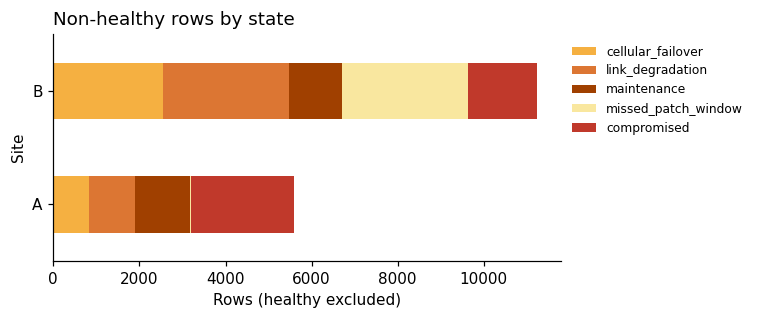

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3))
order = ["cellular_failover", "link_degradation", "maintenance", "missed_patch_window", "compromised"]
detail[order].plot.barh(stacked=True, ax=ax,
    color=["#f5b041", "#dc7633", "#a04000", "#f9e79f", "#c0392b"])
ax.set_xlabel("Rows (healthy excluded)"); ax.set_ylabel("Site")
ax.set_title("Non-healthy rows by state", loc="left")
ax.legend(frameon=False, bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout(); FIGS["state_mix"] = fig; plt.show()

> **Notes:** Compromise is rare by design: ~3.6% of rows at A, ~2.4% at B (target 1–5%).
> - 28 / 18 compromised devices, enough for a device-level train/test split
> - Site B has ~3× the degraded rows: noisier links, slower patching
> - Missed-patch rows go from 31 at A to ~2,900 at B, so shift shows up in the hard negatives too, and not only the features

### 4. Mean Feature Value by Site and State

Heatmap of mean values by site and state.

In [ ]:
prof = both.groupby(["site", "label"])[NUMERIC].mean().T
display(prof.style.format("{:.3f}").background_gradient(axis=1, cmap="Reds"))

> **Notes:** Mean feature values by site and state, with darker cells being higher.
> - Compromised rows differ from healthy ones mostly in template compliance, version changes, and key changes
> - Degraded rows are elevated on the channel metrics; compromised rows mostly aren't
> - `cert_valid` = 1.000 in every column (Matches the core claim from my prior paper)

###5. Difficulty Check - Single-Feature Pr-AUC (Site A)

If a feature approaches 1.0 the task is trivial, indicating overweighted variable. Dashed line = chance. PR-AUC against Chance.

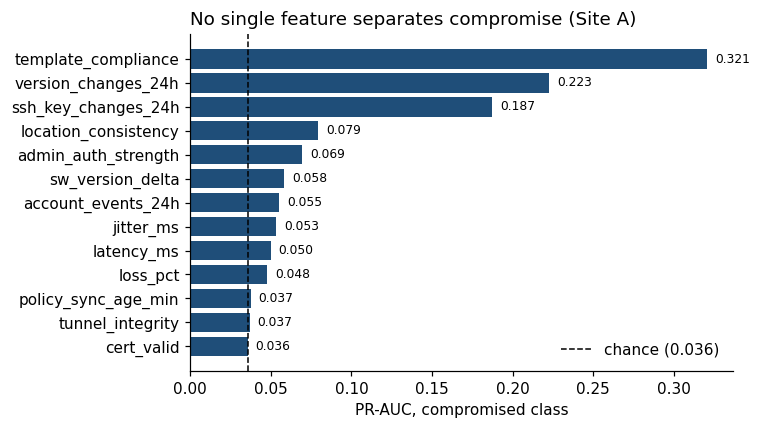

In [ ]:
base = A.is_compromised.mean()
uni = pd.Series({f: average_precision_score(A.is_compromised, RISK_SIGN[f] * A[f].astype(float))
                 for f in NUMERIC}).sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(uni.index, uni.values, color=COLORS["A"])
ax.axvline(base, color="k", ls="--", lw=1, label=f"chance ({base:.3f})")
for i, v in enumerate(uni.values):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=8)
ax.set_xlabel("PR-AUC, compromised class")
ax.set_title("No single feature separates compromise (Site A)", loc="left")
ax.legend(frameon=False)
plt.tight_layout(); FIGS["univariate_prauc"] = fig; plt.show()

> **Notes:** Each feature used alone as a detector, scored by PR-AUC against a chance level of 0.036.
> - The best single feature (template compliance) reaches only 0.32, so the task isn't trivial
> - That leaves room for combining features, which is what both the baseline and the learned models do
> - `cert_valid` sits exactly at chance. The certificate carries zero detection value

###6. Cross-site shift - KS statistic on Healthy Rows (A vs. B)

CHannel features shift while attack-relevent features do not.

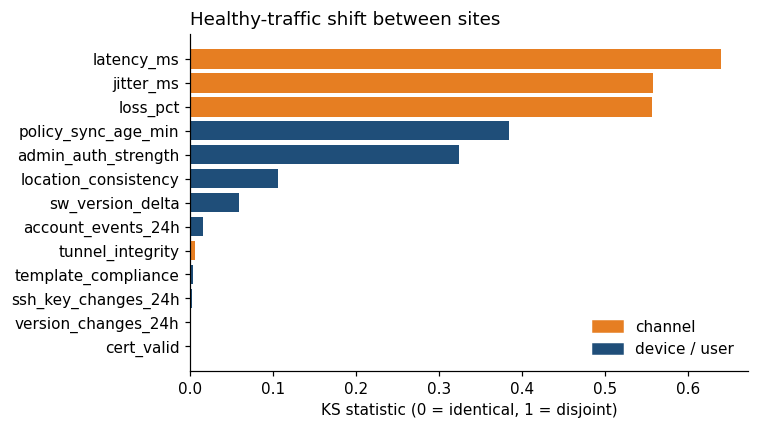

transport_class,broadband,cellular,mpls
site,,,
A,32.5%,7.2%,60.3%
B,53.4%,31.1%,15.5%


In [ ]:
hA, hB = A[A.label == "healthy"], B[B.label == "healthy"]
ks = pd.Series({f: (ks_2samp(hA[f], hB[f]).statistic
                    if hA[f].nunique() + hB[f].nunique() > 2 else 0.0)
                for f in NUMERIC}).sort_values()

channel = {"tunnel_integrity", "latency_ms", "jitter_ms", "loss_pct"}
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(ks.index, ks.values,
        color=[COLORS["B"] if f in channel else COLORS["A"] for f in ks.index])
ax.set_xlabel("KS statistic (0 = identical, 1 = disjoint)")
ax.set_title("Healthy-traffic shift between sites", loc="left")
ax.legend(handles=[plt.Rectangle((0,0),1,1,color=COLORS["B"]),
                   plt.Rectangle((0,0),1,1,color=COLORS["A"])],
          labels=["channel", "device / user"], frameon=False, loc="lower right")
plt.tight_layout(); FIGS["ks_shift"] = fig; plt.show()

display(both.groupby("site").transport_class.value_counts(normalize=True)
        .unstack().style.format("{:.1%}"))

> **Notes:** Distribution shift between sites on healthy traffic only (0 = identical, 1 = disjoint).
> - Channel metrics shift heavily (KS ~0.56–0.64)
> - The attack-relevant features barely shift (KS < 0.01)
> - The environment changes and the adversary doesn't, so any cross-site performance drop is attributable to environmental shift

###7. Channel Telemetry Distributions, Site A vs Site B

Latency, jitter, and loss measurements between sites. Site A has less of each than site B.

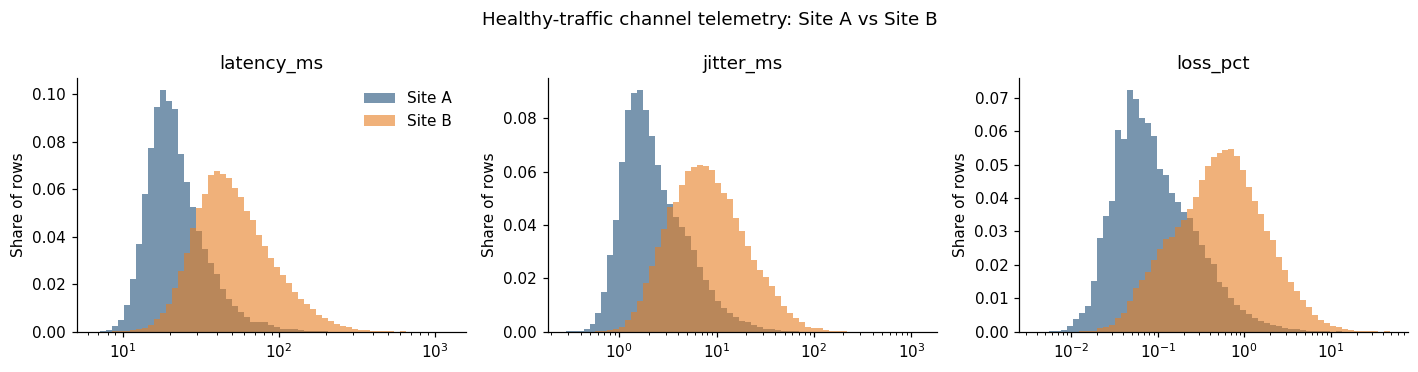

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, f in zip(axes, ["latency_ms", "jitter_ms", "loss_pct"]):
    bins = np.logspace(np.log10(max(both[f].min(), 1e-3)), np.log10(both[f].max()), 60)
    for site, h in [("A", hA), ("B", hB)]:
        ax.hist(h[f], bins=bins, alpha=0.6, weights=np.full(len(h), 1 / len(h)),
                label=f"Site {site}", color=COLORS[site])
    ax.set_xscale("log"); ax.set_title(f); ax.set_ylabel("Share of rows")
axes[0].legend(frameon=False)
fig.suptitle("Healthy-traffic channel telemetry: Site A vs Site B")
plt.tight_layout(); FIGS["site_shift"] = fig; plt.show()

> **Notes:** The same metric gets a different meaning at each site.
> - 45 ms latency is normal at B and an outlier at A
> - Metrics are emitted raw rather than as deviation from a site baseline to better emulate reality and allow for cross-site shift
> - Per-site normalization is a planned ablation study to further isolate which features can be further engineered and which cannot (Feedback is appreciated)

###8. Device Timeline - Rollback-and-Restore with Constant Certificate

Change the device to any id, or leave none to auto-select a device with a rollback. Rollback-and-Restore(RAR) was the main indicator of compromise in the 2023 attacks. This shows the RAR changing as the certificate remains the same.

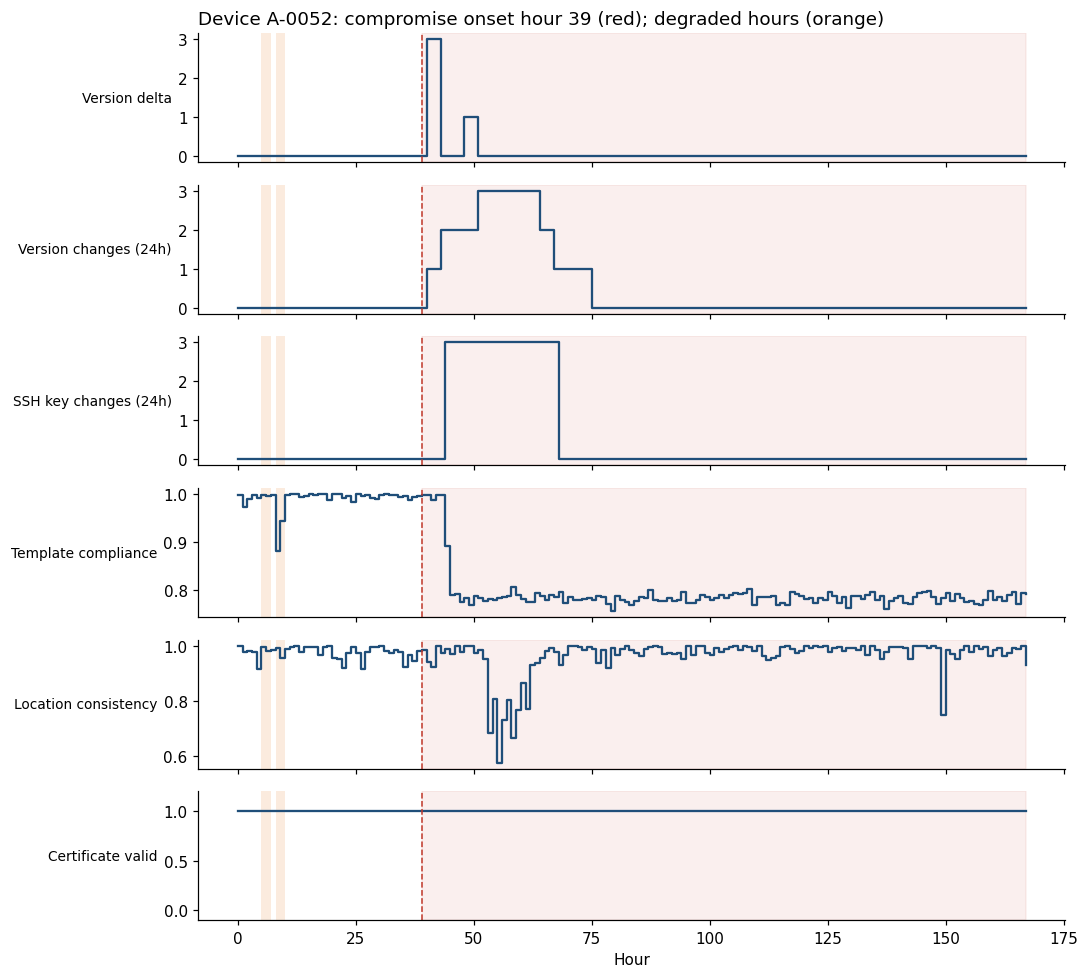

                     min  max
stage                        
initial_access        39   39
rollback              40   42
restore               43   43
persistence           44   44
config_manipulation   45  167


In [ ]:
def plot_device(df, device_id):
    d = df[df.device_id == device_id]
    panels = [("sw_version_delta", "Version delta"),
              ("version_changes_24h", "Version changes (24h)"),
              ("ssh_key_changes_24h", "SSH key changes (24h)"),
              ("template_compliance", "Template compliance"),
              ("location_consistency", "Location consistency"),
              ("cert_valid", "Certificate valid")]
    fig, axes = plt.subplots(len(panels), 1, figsize=(10, 9), sharex=True)
    onset = d.loc[d.is_compromised == 1, "t"].min()
    for ax, (col, name) in zip(axes, panels):
        ax.step(d.t, d[col], where="post", color=COLORS["A"])
        # shade benign degraded episodes
        for t in d.loc[d.label == "degraded", "t"]:
            ax.axvspan(t, t + 1, color=COLORS["degraded"], alpha=0.15, lw=0)
        if pd.notna(onset):
            ax.axvspan(onset, d.t.max(), color=COLORS["compromised"], alpha=0.08)
            ax.axvline(onset, color=COLORS["compromised"], lw=1, ls="--")
        ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=9)
    axes[-1].set_ylim(-0.1, 1.2); axes[-1].set_xlabel("Hour")
    title = f"Device {device_id}"
    title += f": compromise onset hour {onset} (red); degraded hours (orange)" if pd.notna(onset) else " (never compromised)"
    axes[0].set_title(title, loc="left")
    plt.tight_layout()
    return fig

DEVICE = None
if DEVICE is None:
    DEVICE = A.loc[A.stage == "rollback", "device_id"].iloc[0]
FIGS["rollback_timeline"] = plot_device(A, DEVICE); plt.show()

# Kill-chain stages this device went through:
print(A[(A.device_id == DEVICE) & (A.stage != "")].groupby("stage", sort=False).t.agg(["min", "max"]))

> **Notes:** One compromised device walking through the documented UAT-8616 kill chain.
> - Rollback → restore: the version returns to normal, but the 24 h change counter keeps the residue
> - Key injection and persistent template drift follow
> - The certificate line never moves indicating certificate validation can't see this attack and attribute-based scoring can

Browse devices using the dropdown below. Compromised devices are listed first.

In [ ]:
import ipywidgets as widgets
ids = (A.groupby("device_id").is_compromised.max().sort_values(ascending=False).index.tolist())
widgets.interact(lambda device_id: (plot_device(A, device_id), plt.show()),
                 device_id=widgets.Dropdown(options=ids, value=ids[0]));

interactive(children=(Dropdown(description='device_id', options=('A-0391', 'A-0398', 'A-0028', 'A-0354', 'A-03…

> **Notes:** Live browsing, with compromised devices listed first.
> - Kill-chain stages fire probabilistically, so some intrusions are loud and some are nearly silent

###9. Hard Negatives Overlap Compromise

Degraded vs compromised states in feature space. Shows why hard negatives matter

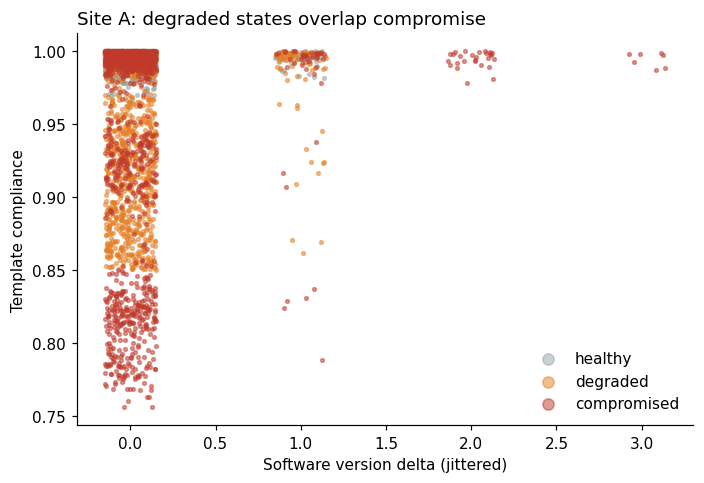

In [ ]:
samp = pd.concat([g.sample(min(len(g), 1500), random_state=0) for _, g in A.groupby("label")])
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for lab in ["healthy", "degraded", "compromised"]:
    g = samp[samp.label == lab]
    ax.scatter(g.sw_version_delta + rng.uniform(-0.15, 0.15, len(g)), g.template_compliance,
               s=6, alpha=0.5, color=COLORS[lab], label=lab)
ax.set_xlabel("Software version delta (jittered)"); ax.set_ylabel("Template compliance")
ax.set_title("Site A: degraded states overlap compromise", loc="left")
ax.legend(frameon=False, markerscale=3)
plt.tight_layout(); FIGS["overlap"] = fig; plt.show()

> **Notes:** Degraded (orange) and compromised (red) occupy the same region of feature space.
> - A missed patch and a shallow rollback both show version delta = 1
> - Maintenance dips template compliance into the same range as attacker drift
> - Hard negatives make false rejects a risk as well as false accepts

###10. Compromised Rows by Kill-chain Stage

Shows share of compromised rows by kill chain stage, with dwell in gray. Helps show dwell time.

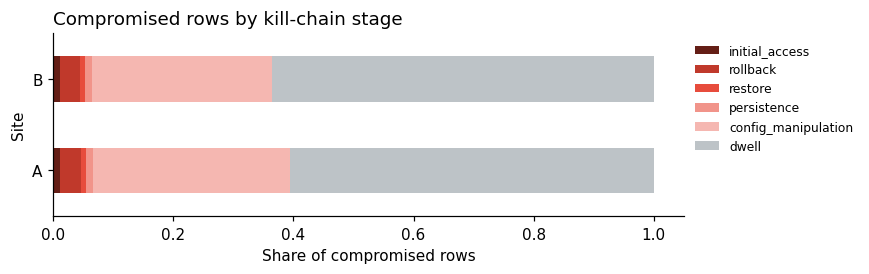

stage,initial_access,rollback,restore,persistence,config_manipulation,dwell
site,,,,,,
A,28,82,21,28,781,1446
B,18,54,13,18,482,1024


In [ ]:
stage_order = ["initial_access", "rollback", "restore", "persistence", "config_manipulation", "dwell"]
st = (both[both.is_compromised == 1].groupby(["site", "stage"]).size()
      .unstack(fill_value=0).reindex(columns=stage_order, fill_value=0))
share = st.div(st.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(8, 2.6))
share.plot.barh(stacked=True, ax=ax,
    color=["#641e16", "#c0392b", "#e74c3c", "#f1948a", "#f5b7b1", "#bdc3c7"])
ax.set_xlabel("Share of compromised rows"); ax.set_ylabel("Site")
ax.set_title("Compromised rows by kill-chain stage", loc="left")
ax.legend(frameon=False, bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout(); FIGS["stage_mix"] = fig; plt.show()
display(st)

> **Notes:** About 60% of compromised rows are dwell, where the attacker is present but quiet.
> - Labeling dwell as compromised, while true, caps achievable per-row recall
> - Reporting per-device recall (has this device been flagged before) may be a useful feature to add to the data-set

###11. Stability Across Seeds

Base rate accross 5 seeds against the 1-5% target band. Evidence of reproducability.

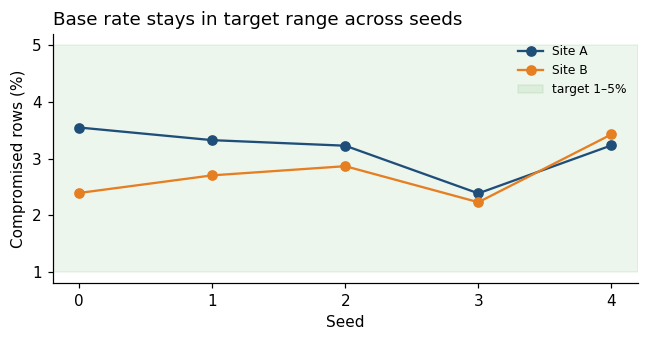

In [ ]:
rows = []
for s in range(5):
    for site, df in generate(DEFAULT_CONFIG, seed=s).items():
        rows.append(dict(seed=s, site=site,
            compromised_devices=df.groupby("device_id").is_compromised.max().sum(),
            compromised_rate=df.is_compromised.mean(),
            degraded_rate=(df.label == "degraded").mean()))
seeds = pd.DataFrame(rows)
display(seeds.groupby("site")[["compromised_devices", "compromised_rate", "degraded_rate"]]
        .agg(["mean", "std"]).style.format("{:.4f}"))

fig, ax = plt.subplots(figsize=(6, 3.2))
for site, g in seeds.groupby("site"):
    ax.plot(g.seed, g.compromised_rate * 100, "o-", color=COLORS[site], label=f"Site {site}")
ax.axhspan(1, 5, color="green", alpha=0.07, label="target 1–5%")
ax.set_xlabel("Seed"); ax.set_ylabel("Compromised rows (%)"); ax.set_xticks(range(5))
ax.set_title("Base rate stays in target range across seeds", loc="left")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); FIGS["seed_stability"] = fig; plt.show()